# ST40 — integrated shear balance, physics-only continuation

**Use the same `RheolNet_ST40_Viscosity_Guarded_Input` dataset. No additional dataset is needed.**
Leave the source/input paths blank and run this new notebook on a T4. No cells have been executed during preparation.

The exact source is the symmetric `final_seed20260923_cont.pt` from `results (10).zip`, packaged as `checkpoint/source_checkpoint.bin`. Its development errors were v=8.4531%, viscosity=22.3347%, pressure=5.0243%. A 5% pass is a measured outcome, not a guarantee.

## What changes
The previous experiment could reject every local direction and return unchanged weights. This version lets a short Adam trajectory evolve, saves every evaluated endpoint, and chooses a protected candidate using physics alone. Final CFD validation evaluates **source, protected candidate, and endpoint diagnostic** independently. The endpoint is not automatically promoted.

The new physics term is centreline-integrated axial momentum. For nondimensional shear stress txy=m(gamma)*(u_y+v_x), symmetry gives txy(x,0)=0, and

    txy(x,y) = Re_H * integral_0^y [u*u_x + v*u_y + p_x - (1/Re_H)*d_x(2*m*u_x)] ds.

All terms come from the current network and prescribed rheology. Pressure and normal-stress contributions remain included. Gauss–Legendre quadrature evaluates the integral. A monotone constitutive inversion converts this stress into a target shear rate, conditioned on the current normal strain components. This targets derivative consistency in the narrow core without using CFD viscosity labels or replacing the viscosity definition.

Training also retains both strong momentum equations, velocity/pressure anchors and the outlet condition. The architecture, rounded geometry, inlet ansatz and physical rheology remain the same. Quadrature and inverse-derivative checks run on Kaggle before optimization.

## Preservation and limits
* No CFD labels enter training, sampling, model selection or stopping.
* The protected candidate must keep sampled regional v/u drift below 1% and pressure drift below 0.5%, preserve the five axial profiles, and satisfy broad regional momentum protections. Local core diagnostics are reported rather than each acting as a separate veto.
* Those are source-drift checks, **not** proof of unchanged CFD error. Final validation separately requires candidate transverse CFD error not to exceed the source error.
* All twelve CFD accuracy gates use 5%. Physics residuals and quadrature checks remain separate numerical/physical diagnostics.
* No direct viscosity target exists in physics-only training. Improving integral consistency may or may not reduce CFD viscosity error. The final comparison reports the actual outcome.
* The earlier rounded-versus-piecewise wall mismatch remains visible; clamped evaluation points are counted. No mesh-gradient viscosity result replaces the primary AD-derived viscosity metric.

## Paths, run budget and resume
Input dataset: same supplied `RheolNet_ST40_Viscosity_Guarded_Input.zip`.
Source payload: `checkpoint/source_checkpoint.bin` (unchanged bytes of `final_seed20260923_cont.pt`).
Training: `training_inputs/physics.json`, `geometry.json`, `inlet_boundary.csv`.
Frozen validation: `validation/full_field.csv`, `validation/profiles/profile_x*.csv`.
Outputs: `/kaggle/working/st40_integrated_shear_v1`.
Default budget: 400 Adam steps, evaluate/save every 50; no automatic L-BFGS or eight-hour restart.
The GPU prints measured timings. Same-output reruns resume `latest.pt`; to resume elsewhere set `RESUME_PATH` to this notebook's latest checkpoint. Do not use the older guarded optimizer checkpoint.

## References and evidence
* Original notebook: `C:/Users/athar/Downloads/task_1_5_st40_continue_symmetric_t4.ipynb`.
* Source archive: `C:/Users/athar/Downloads/results (10).zip`.
* [RheolNet source commit](https://github.com/ath4trva/RheolNet/tree/391575f7014018b295cf9faf98c7171b8b258f8e), branch `Atharva_pinn-core-baseline`.
* [OpenFOAM Bird–Carreau model](https://cpp.openfoam.org/v13/classFoam_1_1laminarModels_1_1generalisedNewtonianViscosityModels_1_1BirdCarreau.html).
* Local case files inspected: `Groud Truth/2D cases/P2D_ST40_Re500/OpenFOAM_case/constant/physicalProperties`, `constant/momentumTransport`, `system/fvSchemes`. Multiplying nu0=5.283018867925e-5 and nuInf=3.301886792453e-6 by rho=1060 agrees with mu0=.056 and muInf=.0035; k=3.313, n=.3568, a=2 also match. These files do not alone verify native exported gradients or mesh convergence.
* [Kharazmi et al., VPINNs](https://arxiv.org/abs/1912.00873) motivates integral formulations. This cross-sectional identity is derived directly above, not a claim to reproduce their method.
* [Berrone et al., quadrature and test functions](https://arxiv.org/abs/2109.02035) motivates explicit quadrature checks.
* [Wang et al., gradient pathologies](https://arxiv.org/abs/2001.04536) motivates conditioning.

Manufactured and inverse-function tests verify implementation only; they cannot certify ST40 accuracy. No publication-pass label is emitted from profile averages.

In [1]:
import gc, hashlib, json, math, os, random, shutil, time, zipfile
from pathlib import Path
from types import SimpleNamespace
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import display

DATASET_DIR = '/kaggle/input/datasets/nightfury22344/rheolnet-st40-viscosity-guarded-input'       # e.g. /kaggle/input/datasets/nightfury22344/rheolnet-st40-viscosity-guarded-input
SOURCE_PATH = ''       # blank locates checkpoint/source_checkpoint.bin in the supplied bundle
RESUME_PATH = ''       # optional latest.pt from THIS notebook; blank = output latest.pt if present
OUT = Path('/kaggle/working/st40_integrated_shear_v1')
K = dict(steps=400, check_every=50, lr=2e-5, microbatch=256,
         area_per_region=128, core_per_stratum=48, join_per_side=48,
         screen_area_per_region=128, screen_core_per_stratum=32, screen_join_per_side=32,
         core_weight=1.0, join_weight=1.0, y_weight=3.0,
         v_drift_limit=0.01, u_drift_limit=0.01, p_drift_limit=0.005,
         profile_u_drift_limit=0.01, physics_growth_limit=1.10,
         anchors_weight=0.05, integral_weight=1.0,
         integral_order=16, integral_sections=4, seed=20261014)
SEED=20260923
QUICK=False
CFG=dict(width=128,depth=5,corner_eps_m=1.5e-4,inlet_blend_H=0.5,
         rel_floor=0.05,gate_regional_rel=0.05,gate_global_rel=0.02,gate_outlet=0.02)
TRAIN_DTYPE, REFINE_DTYPE=torch.float32,torch.float64
if not torch.cuda.is_available(): raise RuntimeError('Select a Kaggle T4 GPU before running.')
device=torch.device('cuda:0')
torch.backends.cuda.matmul.allow_tf32=False
torch.backends.cudnn.allow_tf32=False
random.seed(K['seed']); np.random.seed(K['seed']); torch.manual_seed(K['seed'])
for sub in ('checkpoints','metrics','figures','fields'): (OUT/sub).mkdir(parents=True,exist_ok=True)
CKPT=OUT/'checkpoints'
GPU_NAME=torch.cuda.get_device_name(0)
COMMIT='391575f7014018b295cf9faf98c7171b8b258f8e'
MODEL_FROZEN=False
def sha(p): return hashlib.sha256(Path(p).read_bytes()).hexdigest()
def jsonable(x):
    if isinstance(x,dict): return {str(k):jsonable(v) for k,v in x.items()}
    if isinstance(x,(list,tuple)): return [jsonable(v) for v in x]
    if isinstance(x,np.generic): return jsonable(x.item())
    if isinstance(x,float) and not math.isfinite(x): return None
    return x
def write_json(p,obj):
    p=Path(p); tmp=p.with_suffix(p.suffix+'.tmp')
    tmp.write_text(json.dumps(jsonable(obj),indent=2,allow_nan=False)); tmp.replace(p)
def atomic_save(obj,p):
    p=Path(p); tmp=p.with_suffix(p.suffix+'.tmp'); torch.save(obj,tmp); tmp.replace(p)
def relative_l2_error(a,b,eps=1e-12):
    a=np.asarray(a,dtype=float).reshape(-1); b=np.asarray(b,dtype=float).reshape(-1)
    assert a.shape==b.shape and np.isfinite(a).all() and np.isfinite(b).all()
    return float(np.linalg.norm(a-b)/max(np.linalg.norm(b),eps))
print('GPU:',GPU_NAME,'| torch:',torch.__version__)

GPU: Tesla T4 | torch: 2.11.0+cu128


In [2]:
import torch


def repo_cy(
    gamma_dot,
    eta0=0.056,
    eta_inf=0.0035,
    lam=3.313,
    n=0.3568,
    a=2.0,
):
    """
    Carreau-Yasuda model for shear-dependent blood viscosity.

    Parameters
    ----------
    gamma_dot : torch.Tensor
        Local shear rate.

    eta0 : float
        Zero-shear viscosity [Pa.s].

    eta_inf : float
        Infinite-shear viscosity [Pa.s].

    lam : float
        Time constant [s].

    n : float
        Power-law index.

    a : float
        Yasuda parameter.

    Returns
    -------
    torch.Tensor
        Local dynamic viscosity.
    """

    gamma_dot = torch.clamp(
        gamma_dot,
        min=0.0,
    )

    eta = (
        eta_inf
        + (eta0 - eta_inf)
        * (
            1.0
            + (lam * gamma_dot) ** a
        ) ** ((n - 1.0) / a)
    )

    return eta

In [3]:
# Locate either attached directories or raw ZIPs without selecting arbitrary checkpoints.
INPUT_ROOT=Path('/kaggle/input')
if not INPUT_ROOT.exists(): raise FileNotFoundError('Kaggle /kaggle/input is absent.')
def safe_extract(z,names,target):
    target=Path(target).resolve(); target.mkdir(parents=True,exist_ok=True)
    for name in names:
        info=z.getinfo(name)
        if info.is_dir(): continue
        dest=(target/name).resolve()
        if not dest.is_relative_to(target): raise RuntimeError('Unsafe ZIP entry: '+name)
        dest.parent.mkdir(parents=True,exist_ok=True)
        with z.open(info) as r,dest.open('wb') as w: shutil.copyfileobj(r,w)

extract_root=OUT/'input_extract'
for zp in sorted(INPUT_ROOT.rglob('*.zip')):
    with zipfile.ZipFile(zp) as z:
        names=z.namelist()
        is_bundle=any(n.endswith('training_inputs/physics.json') for n in names)
        is_results=any(n.endswith('/final_seed20260923_cont.pt') or n.endswith('checkpoint/source_checkpoint.bin') for n in names)
        if not (is_bundle or is_results): continue
        wanted=[n for n in names if (is_bundle and ('training_inputs/' in n or 'validation/' in n))
                or (is_results and (n.endswith('/final_seed20260923_cont.pt') or n.endswith('checkpoint/source_checkpoint.bin')))]
        safe_extract(z,wanted,extract_root/sha(zp)[:12])
roots=[INPUT_ROOT,extract_root] if extract_root.exists() else [INPUT_ROOT]

if DATASET_DIR:
    BUNDLE=Path(DATASET_DIR)
    if not (BUNDLE/'training_inputs/physics.json').is_file(): raise FileNotFoundError(DATASET_DIR)
else:
    bundles=sorted({p.parent.parent for root in roots for p in root.rglob('physics.json')
                    if p.parent.name=='training_inputs' and (p.parent.parent/'validation/full_field.csv').is_file()})
    if not bundles: raise RuntimeError('Attach the ST40 core/downstream physics bundle.')
    identities={tuple(sha(p/'training_inputs'/n) for n in ('physics.json','geometry.json','inlet_boundary.csv')) for p in bundles}
    if len(identities)!=1: raise RuntimeError('Different input bundles found. Set DATASET_DIR explicitly: '+str(bundles))
    BUNDLE=bundles[0]  # identical-content duplicates only

def checkpoint_file(path):
    path=Path(path)
    if path.is_file(): return path
    if not (path/'data.pkl').is_file(): raise FileNotFoundError('Checkpoint FILE/serialization directory absent: '+str(path))
    rebuilt=extract_root/('repacked_'+hashlib.sha256(str(path).encode()).hexdigest()[:12]+'.pt')
    rebuilt.parent.mkdir(parents=True,exist_ok=True)
    with zipfile.ZipFile(rebuilt,'w',compression=zipfile.ZIP_STORED) as z:
        for p in sorted(path.rglob('*')):
            if p.is_file(): z.write(p,'checkpoint/'+p.relative_to(path).as_posix())
    return rebuilt

if SOURCE_PATH:
    source_original=Path(SOURCE_PATH)
else:
    matches=sorted({p for root in roots for name in ('final_seed20260923_cont.pt','source_checkpoint.bin') for p in root.rglob(name)})
    if not matches: raise RuntimeError('Attach results (10) output containing final_seed20260923_cont.pt.')
    files=[p for p in matches if p.is_file()]
    if files and len({sha(p) for p in files})==1 and len(files)==len(matches): source_original=files[0]
    elif len(matches)==1: source_original=matches[0]
    else: raise RuntimeError('Multiple source identities. Set SOURCE_PATH explicitly: '+str(matches))
SOURCE=checkpoint_file(source_original)
EXPECTED_SOURCE_SHA='57e437a221b243b5f2d3f90ba11b31af48b6cb8f8f4387108743dfbf84a73449'
if source_original.is_file() and sha(SOURCE)!=EXPECTED_SOURCE_SHA:
    raise RuntimeError('Wrong starting checkpoint SHA256. Expected the exact results (10) continuation file.')
VAL_DIR=BUNDLE/'validation'
TRAIN_HASHES={n:sha(BUNDLE/'training_inputs'/n) for n in ('physics.json','geometry.json','inlet_boundary.csv')}
PHYS=json.loads((BUNDLE/'training_inputs/physics.json').read_text())
GEOM=json.loads((BUNDLE/'training_inputs/geometry.json').read_text())
boundary=pd.read_csv(BUNDLE/'training_inputs/inlet_boundary.csv')
class SealedCFD:
    def __init__(self,val_dir):
        self.field=val_dir/'full_field.csv'; self.profiles=sorted((val_dir/'profiles').glob('profile_x*.csv'))
        if not self.field.is_file() or len(self.profiles)!=5: raise RuntimeError('Need full_field.csv and five profiles.')
        self.fingerprint={p.name:sha(p) for p in [self.field,*self.profiles]}
    def _check(self):
        if not MODEL_FROZEN: raise PermissionError('CFD labels remain sealed during optimization.')
    def load_field(self): self._check(); return pd.read_csv(self.field).sort_values(['x','y']).reset_index(drop=True)
    def load_profiles(self): self._check(); return [(p.name,pd.read_csv(p).sort_values('y')) for p in self.profiles]
SEALED=SealedCFD(VAL_DIR)
metadata=dict(mean_inlet_velocity_m_s=float(boundary.u_m_s.mean()))
_H,_HT,_L=GEOM['healthy_height_m']/2,GEOM['throat_height_m']/2,GEOM['total_length_m']
_xs=[GEOM[k] for k in ('converging_start_m','throat_start_m','throat_end_m','diverging_end_m')]
geometry=SimpleNamespace(healthy_half_height_m=_H,throat_half_height_m=_HT,total_length_m=_L,
    severity_percent=GEOM['severity_percent'],
    converging_start_m=_xs[0],throat_start_m=_xs[1],throat_end_m=_xs[2],diverging_end_m=_xs[3],
    half_height=lambda x:np.interp(np.asarray(x),[0,*_xs,_L],[_H,_H,_HT,_HT,_H,_H]))
inlet=SimpleNamespace(y_m=boundary.y_m.to_numpy(),u_m_s=boundary.u_m_s.to_numpy())
rho=float(PHYS['rho_kg_m3'])
ETA0,ETA_INF,LAM,POWER_N,YASUDA_A=(float(PHYS[k]) for k in ('mu0_Pa_s','muInf_Pa_s','lambda_s','n','a'))
assert PHYS['case_id']=='P2D_ST40_Re500' and GEOM['severity_percent']==40
assert np.allclose([_L,_H,_HT,*_xs],[.092,.003,.0018,.030,.042,.050,.062])
assert float(boundary.v_m_s.abs().max())<1e-10
print('BUNDLE:',BUNDLE,'\nSOURCE:',source_original,'\nOUTPUT:',OUT)

BUNDLE: /kaggle/input/datasets/nightfury22344/rheolnet-st40-viscosity-guarded-input 
SOURCE: /kaggle/input/datasets/nightfury22344/rheolnet-st40-viscosity-guarded-input/checkpoint/source_checkpoint.bin 
OUTPUT: /kaggle/working/st40_integrated_shear_v1


In [4]:
H, L, HT = geometry.healthy_half_height_m, geometry.total_length_m, geometry.throat_half_height_m
U = float(metadata["mean_inlet_velocity_m_s"]); Q_PHYS = 2 * H * U
RE_H, M0, LAMBDA_ND = rho * U * H / ETA_INF, ETA0 / ETA_INF, LAM * U / H
LX, HT_ND, Q_ND = L / H, HT / H, 2.0
X1, X2, X3, X4 = (v / H for v in (geometry.converging_start_m, geometry.throat_start_m, geometry.throat_end_m, geometry.diverging_end_m))
REGIONS = dict(upstream=(0, X1), converging=(X1, X2), throat=(X2, X3), diffuser=(X3, X4), recovery=(X4, LX))
PROFILE_X_M = [0.015, 0.036, 0.046, 0.056, 0.077]
display(pd.Series(dict(Re_2H=2 * RE_H, Re_H=RE_H, m0=M0, Lambda=LAMBDA_ND, n=POWER_N, a=YASUDA_A, L_over_H=LX,
                       throat_over_H=HT_ND, severity=geometry.severity_percent), name="value").to_frame())

,value
Re_2H,500.023200
Re_H,250.011600
m0,16.000000
Lambda,303.879404
n,0.356800
a,2.000000
L_over_H,30.666667
throat_over_H,0.600000
severity,40.000000


In [5]:
from numpy.polynomial import chebyshev as cheb
eta_in = inlet.y_m / H
inlet_asym = float(np.linalg.norm(inlet.u_m_s - inlet.u_m_s[::-1]) / np.linalg.norm(inlet.u_m_s + inlet.u_m_s[::-1]))
u_sym = .5 * (inlet.u_m_s + inlet.u_m_s[::-1])
coef = np.linalg.lstsq(cheb.chebvander(eta_in, 24) * (1 - eta_in ** 2)[:, None], u_sym, rcond=None)[0]
u_coef = cheb.chebmul(coef, [.5, 0, -.5])  # (1-eta^2) = 0.5*T0 - 0.5*T2
F_coef = cheb.chebint(u_coef); F_coef[0] -= cheb.chebval(-1, F_coef); F_coef /= cheb.chebval(1, F_coef)
u_mean_fit = .5 * (cheb.chebval(1, cheb.chebint(u_coef)) - cheb.chebval(-1, cheb.chebint(u_coef)))
INLET_FIT_L2 = relative_l2_error(cheb.chebval(eta_in, u_coef) * U / u_mean_fit, inlet.u_m_s)
INLET_MEAN_ERR = abs(inlet.u_m_s.mean() * 2 * H / Q_PHYS - 1)
print(f"inlet fit L2={100*INLET_FIT_L2:.4f}% | inlet asymmetry={100*inlet_asym:.4f}% | supplied-profile flux error={100*INLET_MEAN_ERR:.3f}%")

inlet fit L2=0.0124% | inlet asymmetry=0.0000% | supplied-profile flux error=0.000%


In [6]:
EPS_ND, ELL = CFG["corner_eps_m"] / H, CFG["inlet_blend_H"]
S1, S2 = (HT_ND - 1) / (X2 - X1), (1 - HT_ND) / (X4 - X3)
def softramp(z): t = z / EPS_ND; return EPS_ND * (torch.relu(t) + torch.log1p(torch.exp(-t.abs())))  # overflow-safe softplus, smooth to all orders
def h_nd(X): return 1 + S1 * (softramp(X - X1) - softramp(X - X2)) + S2 * (softramp(X - X3) - softramp(X - X4))
def h_exact_nd(X): return geometry.half_height(np.asarray(X) * H) / H
def blend(X): return (1 - torch.exp(-X / ELL)) ** 2
def cheb_eval(x, c):
    b1 = b2 = torch.zeros_like(x)
    for ck in torch.flip(c, dims=[0]): b1, b2 = 2 * x * b1 - b2 + ck, b1
    return b1 - x * b2
xs = np.linspace(0, LX, 200001)
GEOM_DEV = float(np.max(np.abs(h_nd(torch.tensor(xs, dtype=torch.float64)).numpy() - h_exact_nd(xs))))
print(f"max wall deviation from blockMesh: {GEOM_DEV*H*1e6:.1f} um = {100*GEOM_DEV/HT_ND:.2f}% of throat half-height")
FEATURE_CENTRES = [X1, X2, X3, X4, X4 + 5.0]

class RWFLinear(nn.Module):
    """Random weight factorization W = diag(exp(s)) V (Wang et al., 2022)."""
    def __init__(self, n_in, n_out, mu=0.5, sigma=0.1):
        super().__init__(); w = torch.empty(n_out, n_in); nn.init.xavier_normal_(w); s = mu + sigma * torch.randn(n_out)
        self.s, self.v, self.b = nn.Parameter(s), nn.Parameter(w / torch.exp(s)[:, None]), nn.Parameter(torch.zeros(n_out))
    def forward(self, x): return F.linear(x, torch.exp(self.s)[:, None] * self.v, self.b)

class ModifiedMLP(nn.Module):
    """Gated MLP with two input encoders (Wang, Teng & Perdikaris, 2021); tanh gives smooth third derivatives."""
    def __init__(self, n_in, width, depth, n_out, out_std):
        super().__init__()
        self.enc_u, self.enc_v, self.inp = RWFLinear(n_in, width), RWFLinear(n_in, width), RWFLinear(n_in, width)
        self.hidden = nn.ModuleList(RWFLinear(width, width) for _ in range(depth - 1))
        self.out = nn.Linear(width, n_out); nn.init.normal_(self.out.weight, std=out_std); nn.init.zeros_(self.out.bias)
    def forward(self, z):
        eu, ev = torch.tanh(self.enc_u(z)), torch.tanh(self.enc_v(z)); g = torch.tanh(self.inp(z)); h = (1 - g) * eu + g * ev
        for layer in self.hidden: g = torch.tanh(layer(h)); h = (1 - g) * eu + g * ev
        return self.out(h)

class BranchPINN(nn.Module):
    def __init__(self, width, depth):
        super().__init__(); n_in = 2 + len(FEATURE_CENTRES)
        self.sym = ModifiedMLP(n_in, width, depth, 2, 0.1 / math.sqrt(width))
        self.asym = ModifiedMLP(n_in, width, depth, 2, 0.02 / math.sqrt(width))
        self.p_slope = nn.Parameter(torch.tensor(0.05))
        # Constants are non-persistent so a float64 model always rebuilds them exactly instead of loading float32 copies.
        self.register_buffer("F_coef", torch.tensor(F_coef), persistent=False); self.register_buffer("centres", torch.tensor(FEATURE_CENTRES), persistent=False)
        self.register_buffer("gate", torch.tensor(0.)); self.register_buffer("sign", torch.tensor(1.))
    def features(self, X, eta): return torch.cat((2 * X / LX - 1, torch.tanh(X - self.centres), eta ** 2), 1)
    def forward(self, XY):
        X, Y = XY[:, :1], XY[:, 1:2]; eta = Y / h_nd(X); z = self.features(X, eta)
        s = self.sym(z); bubble = blend(X) * (1 - eta ** 2) ** 2
        psi = Q_ND * cheb_eval(eta, self.F_coef) + bubble * eta * s[:, :1]
        p = s[:, 1:2] + self.p_slope * (LX - X)
        if float(self.gate) != 0.0:
            a = self.asym(z); k = self.gate * self.sign
            psi = psi + k * bubble * a[:, :1]; p = p + k * eta * a[:, 1:2]
        return psi, p

def build_model(dtype=TRAIN_DTYPE): return BranchPINN(CFG["width"], CFG["depth"]).to(device=device, dtype=dtype)
def dtype_of(net): return next(net.parameters()).dtype
def cpu_state(net): return {k: v.detach().cpu().clone() for k, v in net.state_dict().items()}
torch.manual_seed(SEED); model = build_model()
print("parameters:", sum(p.numel() for p in model.parameters()))

max wall deviation from blockMesh: 10.4 um = 0.58% of throat half-height
parameters: 140549


In [7]:
VISC = dict(m0=M0, lam=LAMBDA_ND, n=POWER_N, a=YASUDA_A)
def viscosity_ratio(g2, v=VISC):
    if v["a"] == 2.0: return 1 + (v["m0"] - 1) * (1 + v["lam"] ** 2 * g2) ** ((v["n"] - 1) / 2)
    return 1 + (v["m0"] - 1) * (1 + (v["lam"] ** 2 * g2 + 1e-30) ** (v["a"] / 2)) ** ((v["n"] - 1) / v["a"])
def D(f, xy, graph=True): return torch.autograd.grad(f, xy, torch.ones_like(f), create_graph=graph, retain_graph=True)[0]

def kinematics(fn, XY, graph=True):
    xy = XY if XY.requires_grad else XY.detach().clone().requires_grad_(True)
    psi, p = fn(xy); g = D(psi, xy); u, v = g[:, 1:2], -g[:, :1]
    gu, gv = D(u, xy), D(v, xy)
    ux, uy, vx, vy = gu[:, :1], gu[:, 1:2], gv[:, :1], gv[:, 1:2]
    g2 = 2 * ux ** 2 + 2 * vy ** 2 + (uy + vx) ** 2
    return dict(xy=xy, psi=psi, p=p, u=u, v=v, ux=ux, uy=uy, vx=vx, vy=vy, g2=g2)

def navier_stokes(fn, XY, visc_scale=1.0, v=VISC, re=None, graph=True):
    k = kinematics(fn, XY, True); xy = k["xy"]; m = viscosity_ratio(k["g2"], v); c = visc_scale / (re or RE_H)
    gp = D(k["p"], xy, True)
    txx, txy, tyy = 2 * m * k["ux"], m * (k["uy"] + k["vx"]), 2 * m * k["vy"]
    dxx, dxy, dyy = D(txx, xy, graph), D(txy, xy, graph), D(tyy, xy, graph)
    cx, cy_ = k["u"] * k["ux"] + k["v"] * k["uy"], k["u"] * k["vx"] + k["v"] * k["vy"]
    vx_, vy_ = c * (dxx[:, :1] + dxy[:, 1:2]), c * (dxy[:, :1] + dyy[:, 1:2])
    scale = torch.sqrt(cx ** 2 + cy_ ** 2) + torch.sqrt(gp[:, :1] ** 2 + gp[:, 1:2] ** 2) + torch.sqrt(vx_ ** 2 + vy_ ** 2)
    k.update(m=m, rx=cx + gp[:, :1] - vx_, ry=cy_ + gp[:, 1:2] - vy_, cont=k["ux"] + k["vy"], scale=scale,
             rel2x=(cx + gp[:, :1] - vx_) ** 2 / scale.clamp_min(CFG["rel_floor"]) ** 2, rel2y=(cy_ + gp[:, 1:2] - vy_) ** 2 / scale.clamp_min(CFG["rel_floor"]) ** 2)
    k["rel2"] = k["rel2x"] + k["rel2y"]
    return k
WY = K["y_weight"]

In [8]:
import sympy as sp
Xs, Ys = sp.symbols("X Y")
def manufactured(lib):
    s, c = (sp.sin, sp.cos) if lib == "sym" else (torch.sin, torch.cos)
    return (lambda X, Y: (s(0.7 * X) * (1 - Y ** 2) ** 2 + 0.3 * Y ** 3 + 0.5 * c(0.4 * X + 0.2 * Y),
                          0.1 * s(X) * c(Y) + 0.05 * X * Y))
def sympy_residual(v):
    psi, p = manufactured("sym")(Xs, Ys); u, w = sp.diff(psi, Ys), -sp.diff(psi, Xs)
    ux, uy, wx, wy = sp.diff(u, Xs), sp.diff(u, Ys), sp.diff(w, Xs), sp.diff(w, Ys)
    g2 = 2 * ux ** 2 + 2 * wy ** 2 + (uy + wx) ** 2
    a = sp.nsimplify(v["a"]); m = 1 + (v["m0"] - 1) * (1 + (v["lam"] ** 2 * g2) ** (a / 2)) ** ((v["n"] - 1) / a)
    rx = u * ux + w * uy + sp.diff(p, Xs) - (sp.diff(2 * m * ux, Xs) + sp.diff(m * (uy + wx), Ys)) / RE_H
    ry = u * wx + w * wy + sp.diff(p, Ys) - (sp.diff(m * (uy + wx), Xs) + sp.diff(2 * m * wy, Ys)) / RE_H
    return sp.lambdify((Xs, Ys), [rx, ry, m], "numpy")
rng = np.random.default_rng(7); pts = np.column_stack((rng.uniform(0, 6, 400), rng.uniform(-0.95, 0.95, 400)))
tf = manufactured("torch"); fn = lambda xy: tf(xy[:, :1], xy[:, 1:2])
OPERATOR = {}
for label, a in (("a=2 (case)", YASUDA_A), ("a=1.7 (general path)", 1.7)):
    v = dict(VISC, a=a); ref = sympy_residual(v)(pts[:, 0], pts[:, 1])
    got = navier_stokes(fn, torch.tensor(pts, dtype=torch.float64, device=device), v=v)
    err = max(float(np.max(np.abs(got[k].detach().cpu().numpy()[:, 0] - np.asarray(r)))) / float(np.max(np.abs(r)))
              for k, r in zip(("rx", "ry", "m"), ref))
    OPERATOR[label] = err; print(f"manufactured-solution max relative error [{label}]: {err:.2e}")
gd = torch.logspace(-3, 4, 200, dtype=torch.float64)
CY_REPO_ERR = float(((ETA_INF * viscosity_ratio((gd * H / U) ** 2)) / repo_cy(gd, ETA0, ETA_INF, LAM, POWER_N, YASUDA_A) - 1).abs().max())
pois = navier_stokes(lambda xy: (1.5 * xy[:, 1:2] - 0.5 * xy[:, 1:2] ** 3, -3 * xy[:, :1] / RE_H),
                     torch.tensor(pts, dtype=torch.float64, device=device), v=dict(VISC, m0=1.0))
POIS_ERR = float(max(pois["rx"].detach().abs().max(), pois["ry"].detach().abs().max()))
print(f"viscosity vs repo carreau_yasuda_viscosity: {CY_REPO_ERR:.2e} | Newtonian Poiseuille residual: {POIS_ERR:.2e}")

manufactured-solution max relative error [a=2 (case)]: 5.18e-16
manufactured-solution max relative error [a=1.7 (general path)]: 1.13e-15
viscosity vs repo carreau_yasuda_viscosity: 2.22e-16 | Newtonian Poiseuille residual: 0.00e+00


## Source identity and physics-only coverage
We retain the source geometry for a paired comparison. Its rounded corners differ from the CFD mesh; exact constraints apply to the rounded wall. This limitation is reported in validation.
All sampling uses training geometry only. Core points span |eta|=0..0.02, 0.02..0.05, 0.05..0.10 in each region. Near-join points cover both sides of each join and the outer band, including previously excluded locations. Exact joins are avoided because the inherited `softramp` implementation has an autograd convention at exactly zero; no geometry/function change is hidden in this experiment.

In [9]:
saved=torch.load(SOURCE,map_location='cpu',weights_only=False)
assert saved.get('used_cfd_labels_for_training') is False
assert saved.get('selected')=='symmetric'
for key in ('width','depth','corner_eps_m','inlet_blend_H'):
    assert saved['config'][key]==CFG[key], f'Architecture/geometry mismatch: {key}'
assert saved['commit']==COMMIT
assert SEALED.fingerprint['full_field.csv']=='761ecb103dbcfad6d2a319c6af31c02832c30fef87a7bf8adcbba465a19c6564'
# For an extracted serialization directory, ZIP metadata changes. Compare tensor bytes with the independently supplied identity below.
def state_hash(state):
    h=hashlib.sha256()
    for name in sorted(state):
        t=state[name].detach().cpu().contiguous()
        h.update(name.encode()); h.update(str(t.dtype).encode()); h.update(str(tuple(t.shape)).encode()); h.update(t.numpy().tobytes())
    return h.hexdigest()
SOURCE_STATE={k:v.clone() for k,v in saved['symmetric'].items()}
SOURCE_MODEL_SHA=state_hash(SOURCE_STATE)
# A repacked directory must be compared with a trusted sidecar generated from the original source on Kaggle.
if source_original.is_dir():
    raise RuntimeError('This source was auto-extracted as a directory. Attach final_seed20260923_cont.pt inside results (10).zip instead; exact file verification is required.')
model.load_state_dict(SOURCE_STATE); model.gate.fill_(0); model.asym.requires_grad_(False)
teacher=build_model(TRAIN_DTYPE); teacher.load_state_dict(SOURCE_STATE); teacher.gate.fill_(0)
for p in teacher.parameters(): p.requires_grad_(False)
EXPERIMENT_ID=hashlib.sha256(json.dumps(dict(settings=K,source=sha(SOURCE),inputs=TRAIN_HASHES,
    implementation='578b81e0103479860a60f392b264d8c8b9c102fdc5ec37075ccdbb02999f3558'),sort_keys=True).encode()).hexdigest()
write_json(OUT/'metrics/input_manifest.json',dict(source=str(source_original),source_file_sha256=sha(SOURCE),
    source_model_sha256=SOURCE_MODEL_SHA,training_inputs=TRAIN_HASHES,cfd_fingerprint=SEALED.fingerprint,
    commit=COMMIT,settings=K,experiment_id=EXPERIMENT_ID,used_cfd_labels_for_training=False))

def sample_groups(seed,area_n,core_n,join_n):
    rng=np.random.default_rng(seed); groups=[]
    def make(name,rid,x,e,weight):
        # h_nd handles smoothing; no labels or solution-based filters.
        xx=torch.tensor(np.asarray(x),device=device,dtype=TRAIN_DTYPE).reshape(-1,1)
        ee=torch.tensor(np.asarray(e),device=device,dtype=TRAIN_DTYPE).reshape(-1,1)
        xy=torch.cat((xx,ee*h_nd(xx)),1).detach()
        groups.append(dict(name=name,region=rid,points=xy,weight=weight))
    bands=[(0,.02),(.02,.05),(.05,.10)]
    for rid,(a,b) in enumerate(REGIONS.values()):
        # Rejection sampling in x for true area distribution, h<=1 in nondimensional units.
        xs=[]
        while len(xs)<area_n:
            x=rng.uniform(a,b,2*area_n)
            hh=h_nd(torch.tensor(x,dtype=torch.float64).reshape(-1,1)).numpy().ravel()
            xs.extend(x[rng.random(len(x))<hh].tolist())
        make(f'area_r{rid}',rid,np.array(xs[:area_n]),rng.uniform(-.995,.995,area_n),1.0/5)
        for band,(lo,hi) in enumerate(bands):
            eta=rng.uniform(lo,hi,core_n)*rng.choice([-1.,1.],core_n)
            make(f'core_r{rid}_b{band}',rid,rng.uniform(a,b,core_n),eta,K['core_weight']/15)
    for j,xj in enumerate((X1,X2,X3,X4)):
        for side in (-1,1):
            x=xj+side*rng.uniform(.001,.15,join_n)
            eta=rng.uniform(.75,.995,join_n)*rng.choice([-1.,1.],join_n)
            make(f'join_{j}_{side}',j if side<0 else j+1,x,eta,K['join_weight']/8)
    return groups

def batch_fields(net,points,residual=True):
    out=[]
    for i in range(0,len(points),K['microbatch']):
        r=navier_stokes(net,points[i:i+K['microbatch']],graph=False) if residual else kinematics(net,points[i:i+K['microbatch']])
        names=('rx','ry','scale','u','v','p') if residual else ('u','v','p')
        out.append(torch.cat([r[n] for n in names],1).detach())
        del r
    return torch.cat(out)

def cache_groups(groups):
    for g in groups:
        f=batch_fields(teacher,g['points'])
        g['teacher']=f[:,3:6].detach()
        # Fixed ratio-of-sums denominator per group, not per-point/model-dependent normalization.
        g['scale2']=max(float(f[:,2].square().mean()),CFG['rel_floor']**2)
        g['rms_x']=float(f[:,0].square().mean().sqrt()); g['rms_y']=float(f[:,1].square().mean().sqrt())
    return groups

train_groups=cache_groups(sample_groups(K['seed'],K['area_per_region'],K['core_per_stratum'],K['join_per_side']))
screens=[cache_groups(sample_groups(s,K['screen_area_per_region'],K['screen_core_per_stratum'],K['screen_join_per_side']))
         for s in (20261112,20261113)]
# Independent u-profile coordinates generated from geometry, not CFD files.
profile_points=[]
for xm in PROFILE_X_M:
    x=torch.full((129,1),xm/H,device=device); e=torch.linspace(-.995,.995,129,device=device).reshape(-1,1)
    pp=torch.cat((x,e*h_nd(x)),1).detach()
    profile_points.append((pp,batch_fields(teacher,pp,False)[:,0:1]))
out_eta=torch.linspace(-.995,.995,128,device=device).reshape(-1,1)
out_x=torch.full_like(out_eta,LX)
OUT_POINTS=torch.cat((out_x,out_eta*h_nd(out_x)),1).detach()
base_out=kinematics(teacher,OUT_POINTS)
BASE_OUT=float((base_out['ux'].square()+base_out['vx'].square()+base_out['p'].square()).mean().sqrt().detach())
del base_out
print('Training points:',sum(len(g['points']) for g in train_groups),'| fixed scales and all source caches ready')

Training points: 1744 | fixed scales and all source caches ready


## Integrated shear and controlled continuation
The trial trajectory can move through intermediate states that would fail source-preservation screens. Only evaluated states satisfying the declared protections and improved fixed physics merit can replace the protected candidate. Every evaluation saves its actual weights, including rejected states. The final endpoint is exported for diagnosis. CFD remains sealed until all optimizer work ends.

In [10]:
def shear_inverse(tau,normal2):
    """Invert tau=m(sqrt(normal2+s*s))*s, with an implicit first derivative.
    Used in parameter loss backprop only, never differentiated spatially twice.
    """
    assert YASUDA_A==2.0
    with torch.no_grad():
        lo=tau.abs()/M0; hi=tau.abs()
        for _ in range(40):
            mid=(lo+hi)/2
            val=viscosity_ratio(normal2+mid.square())*mid
            lo=torch.where(val<tau.abs(),mid,lo)
            hi=torch.where(val>=tau.abs(),mid,hi)
        s0=tau.sign()*(lo+hi)/2
    base=1+LAMBDA_ND**2*(normal2+s0.square())
    mu=viscosity_ratio(normal2+s0.square())
    dm_ds=(M0-1)*(POWER_N-1)*LAMBDA_ND**2*s0*base.pow((POWER_N-3)/2)
    denominator=(mu+s0*dm_ds).detach()
    if not torch.isfinite(denominator).all() or not (denominator>0).all():
        raise FloatingPointError('Constitutive inverse lost monotonicity.')
    return s0+(tau-mu*s0)/denominator

def integral_stress(net,targets,order,graph=True,viscosity_fn=viscosity_ratio):
    z,w=np.polynomial.legendre.leggauss(order)
    zz=torch.tensor((z+1)/2,device=targets.device,dtype=targets.dtype)
    ww=torch.tensor(w/2,device=targets.device,dtype=targets.dtype)
    # x is fixed along the integration line; actual Cartesian y runs from 0 to target y.
    xx=targets[:,0:1].expand(-1,order)
    yy=targets[:,1:2]*zz.reshape(1,-1)
    qp=torch.stack((xx,yy),-1).reshape(-1,2).detach().requires_grad_(True)
    k=kinematics(net,qp)
    m=viscosity_fn(k['g2'])
    gp=D(k['p'],qp,graph)
    dxx=D(2*m*k['ux'],qp,graph)[:,0:1]
    integrand=k['u']*k['ux']+k['v']*k['uy']+gp[:,0:1]-dxx/RE_H
    return RE_H*targets[:,1:2]*(integrand.reshape(-1,order)*ww).sum(1,keepdim=True)

ETAS=np.array([.003,.008,.015,.025,.04,.065,.10,.20,.40,.65,.85,.97])
def target_bank(seed,sections_per_region):
    rng=np.random.default_rng(seed); parts=[]
    for a,b in REGIONS.values():
        xx=rng.uniform(a+1e-4,b-1e-4,sections_per_region)
        x=torch.tensor(np.repeat(xx,len(ETAS)),device=device,dtype=TRAIN_DTYPE).reshape(-1,1)
        eta=torch.tensor(np.tile(ETAS,len(xx)),device=device,dtype=TRAIN_DTYPE).reshape(-1,1)
        parts.append(torch.cat((x,eta*h_nd(x)),1).detach())
    targets=torch.cat(parts); scales=[]
    for batch in targets.split(K['microbatch']):
        r=kinematics(teacher,batch)
        scales.append((1/LAMBDA_ND+torch.sqrt(r['g2'])).detach())
    return targets,torch.cat(scales)

TRAIN_TARGETS,TRAIN_SCALES=target_bank(20261014,16)
CHECK_TARGETS,CHECK_SCALES=target_bank(20261114,2)
def integral_loss(net,targets,scales,order,backward=False):
    total=0.; n=len(targets)
    # Bound quadrature AD graph size to roughly microbatch points.
    for start in range(0,n,max(1,K['microbatch']//order)):
        end=min(n,start+max(1,K['microbatch']//order))
        p=targets[start:end]; tau=integral_stress(net,p,order,graph=backward)
        r=kinematics(net,p)
        predicted_s=r['uy']+r['vx']
        target_s=shear_inverse(tau,2*r['ux'].square()+2*r['vy'].square())
        loss=((predicted_s-target_s)/scales[start:end]).square().sum()/n
        if not torch.isfinite(loss): raise FloatingPointError('Nonfinite integral-shear loss.')
        if backward: (K['integral_weight']*loss).backward()
        total+=float(loss.detach())
    return total

# Numerical checks run only when this cell is executed on Kaggle.
t=torch.tensor([-.8,-.02,0.,.02,.8],device=device,dtype=torch.float64,requires_grad=True)
n2=torch.tensor([.03,.001,.001,.001,.03],device=device,dtype=torch.float64,requires_grad=True)
s=shear_inverse(t,n2)
assert torch.allclose(viscosity_ratio(n2+s.square())*s,t,atol=1e-9,rtol=1e-8)
assert torch.autograd.gradcheck(shear_inverse,(t,n2),eps=1e-6,atol=1e-5,rtol=1e-3)
# A centred finite difference in normal2 at zero leaves its physical domain.
# Test that boundary separately without perturbing a squared strain negative.
zero=torch.zeros(1,device=device,dtype=torch.float64)
assert torch.equal(shear_inverse(zero,zero),zero)
# Test the actual Cartesian quadrature/operator code on a Newtonian manufactured flow.
poiseuille=lambda xy:(1.5*xy[:,1:2]-.5*xy[:,1:2]**3,-3*xy[:,0:1]/RE_H)
test_xy=torch.tensor([[.3,.001],[.8,.02],[1.2,.1],[2.1,.5],[3.2,.9]],device=device,dtype=torch.float64)
numerical=integral_stress(poiseuille,test_xy,16,False,lambda g2:torch.ones_like(g2))
assert torch.allclose(numerical,-3*test_xy[:,1:2],atol=1e-10,rtol=1e-10)
# Verify the actual network integral quadrature at the planned order vs doubled order.
test_points=CHECK_TARGETS[::12].clone()  # very near core
test_outer=CHECK_TARGETS[11::12].clone()
test_points=torch.cat((test_points,test_outer))
q1=integral_stress(teacher,test_points,K['integral_order'],False).detach()
q2=integral_stress(teacher,test_points,2*K['integral_order'],False).detach()
quadrature_rel=float(torch.linalg.vector_norm(q1-q2)/torch.linalg.vector_norm(q2).clamp_min(1e-8))
print('Inverse and manufactured shear checks passed. Integral quadrature relative difference:',quadrature_rel)
if quadrature_rel>.02:
    raise RuntimeError('Quadrature unresolved (>2%). Set integral_order=32 and rerun from setup before training.')
BASE_INTEGRAL=integral_loss(teacher,CHECK_TARGETS,CHECK_SCALES,2*K['integral_order'])
write_json(OUT/'metrics/integral_preflight.json',dict(quadrature_relative=quadrature_rel,source_integral_loss=BASE_INTEGRAL))
def screen_report(net):
    ratios=[]; core_ratios=[]; rejected=[]; rows=[]
    max_v=max_u=max_p=0.0
    for si,groups in enumerate(screens):
        for g in groups:
            f=batch_fields(net,g['points']); ref=g['teacher']; name=f's{si}_{g["name"]}'
            rmsx=float(f[:,0].square().mean().sqrt()); rmsy=float(f[:,1].square().mean().sqrt())
            rx=rmsx/max(g['rms_x'],.005); ry=rmsy/max(g['rms_y'],.005)
            ratios.extend([rx*rx,ry*ry])
            if g['name'].startswith('core'): core_ratios.extend([rx*rx,ry*ry])
            for label,value,limit in [('x_growth',rx,K['physics_growth_limit']),('y_growth',ry,K['physics_growth_limit'])]:
                if g['name'].startswith('area') and value>limit: rejected.append(name+'_'+label)
            def drift(col,floor):
                return float(((f[:,col]-ref[:,col-3]).square().mean()/ref[:,col-3].square().mean().clamp_min(floor)).sqrt())
            du,dv,dp=drift(3,1e-6),drift(4,1e-8),drift(5,1e-6)
            if g['name'].startswith('area'):
                max_u,max_v,max_p=max(max_u,du),max(max_v,dv),max(max_p,dp)
            rows.append(dict(screen=si,group=g['name'],x_rms=rmsx,y_rms=rmsy,x_ratio=rx,y_ratio=ry,u_drift=du,v_drift=dv,p_drift=dp))
    for label,value,limit in [('v_drift',max_v,K['v_drift_limit']),('u_drift',max_u,K['u_drift_limit']),('p_drift',max_p,K['p_drift_limit'])]:
        if value>limit: rejected.append(label)
    prof=[]
    for p,ref in profile_points:
        u=batch_fields(net,p,False)[:,0:1]
        prof.append(float(((u-ref).square().sum()/ref.square().sum().clamp_min(1e-8)).sqrt()))
    if max(prof)>K['profile_u_drift_limit']: rejected.append('profile_u_drift')
    o=kinematics(net,OUT_POINTS)
    outlet=float((o['ux'].square()+o['vx'].square()+o['p'].square()).mean().sqrt().detach()); del o
    if outlet>max(.02,BASE_OUT*K['physics_growth_limit']): rejected.append('outlet')
    merit=.5*np.mean(ratios)+.5*np.mean(core_ratios)
    return dict(merit=float(merit),eligible=not rejected,rejected=rejected,max_v_drift=max_v,max_u_drift=max_u,
                max_p_drift=max_p,profile_u_drift=max(prof),outlet=outlet,groups=rows)


def evaluate(net):
    r=screen_report(net)
    r['bulk_merit']=r['merit']
    r['integral_shear_loss']=integral_loss(net,CHECK_TARGETS,CHECK_SCALES,2*K['integral_order'])
    r['integral_ratio']=r['integral_shear_loss']/max(BASE_INTEGRAL,1e-10)
    r['merit']=.5*r['bulk_merit']+.5*r['integral_ratio']
    return r

initial_report=evaluate(model)
assert initial_report['eligible'] and initial_report['max_v_drift']<1e-6
write_json(OUT/'metrics/source_physics.json',initial_report)
params=[p for p in model.parameters() if p.requires_grad]
opt=torch.optim.Adam(params,lr=K['lr'])
rng=torch.Generator(device=device); rng.manual_seed(K['seed'])
history=[]; next_step=0; best_state={n:t.clone() for n,t in SOURCE_STATE.items()}; best_report=initial_report
resume=Path(RESUME_PATH) if RESUME_PATH else CKPT/'latest.pt'
if resume.is_file():
    rr=torch.load(resume,map_location='cpu',weights_only=False)
    assert rr['experiment_id']==EXPERIMENT_ID,'Wrong resume checkpoint/configuration.'
    model.load_state_dict(rr['model']); opt.load_state_dict(rr['optimizer']); rng.set_state(rr['rng'].cpu())
    history=rr['history']; next_step=rr['next_step']; best_state=rr['best_state']; best_report=rr['best_report']
elif RESUME_PATH: raise FileNotFoundError(RESUME_PATH)

def save_latest():
    atomic_save(dict(experiment_id=EXPERIMENT_ID,model=cpu_state(model),optimizer=opt.state_dict(),rng=rng.get_state(),
        best_state=best_state,best_report=best_report,history=history,next_step=next_step,
        source_file_sha256=sha(SOURCE),used_cfd_labels_for_training=False),CKPT/'latest.pt')
    write_json(OUT/'metrics/history.json',history)

def objective_backward():
    opt.zero_grad(set_to_none=True); total=0.
    for g in train_groups:
        # Fresh subset of the physics bank; teacher references and scales stay fixed.
        idx=torch.randperm(len(g['points']),generator=rng,device=device)[:32]
        r=navier_stokes(model,g['points'][idx],graph=True); ref=g['teacher'][idx]
        q=(r['rx'].square()+K['y_weight']*r['ry'].square()).mean()/g['scale2']
        anchor=0
        for col,name,floor in [(0,'u',1e-6),(1,'v',1e-8),(2,'p',1e-6)]:
            anchor=anchor+(r[name]-ref[:,col:col+1]).square().mean()/g['teacher'][:,col].square().mean().clamp_min(floor)
        loss=g['weight']*(q+K['anchors_weight']*anchor); loss.backward(); total+=float(loss.detach())
    section_ids=torch.randperm(len(TRAIN_TARGETS)//len(ETAS),generator=rng,device=device)[:K['integral_sections']]
    ids=(section_ids[:,None]*len(ETAS)+torch.arange(len(ETAS),device=device)[None,:]).flatten()
    integral=integral_loss(model,TRAIN_TARGETS[ids],TRAIN_SCALES[ids],K['integral_order'],True)
    r=kinematics(model,OUT_POINTS)
    out=(r['ux'].square()+r['vx'].square()+r['p'].square()).mean()
    out.backward(); total+=float(out.detach())+K['integral_weight']*integral
    return total,integral

t0=time.perf_counter(); first_step=next_step
try:
    for step in range(next_step,K['steps']):
        # No trial rollback during ordinary optimization: constrained selection is separate.
        loss,integ=objective_backward()
        if not math.isfinite(loss) or any(p.grad is not None and not torch.isfinite(p.grad).all() for p in params):
            raise FloatingPointError('Nonfinite objective/gradient; last periodic checkpoint remains available.')
        torch.nn.utils.clip_grad_norm_(params,1.0)
        opt.step(); next_step=step+1
        if next_step%10==0: print(f'Integrated shear {next_step}/{K["steps"]}: objective={loss:.6g}, shear={integ:.6g}, elapsed={(time.perf_counter()-t0)/60:.1f} min',flush=True)
        if next_step%K['check_every']==0 or next_step==K['steps']:
            report=evaluate(model)
            accepted=report['eligible'] and report['merit']<best_report['merit'] and report['integral_ratio']<1.0
            state=cpu_state(model)
            atomic_save(dict(model=state,step=next_step,report=report,experiment_id=EXPERIMENT_ID,
                used_cfd_labels_for_training=False),CKPT/f'evaluated_step_{next_step:05d}.pt')
            if accepted: best_state=state; best_report=report
            history.append(dict(block=next_step,loss=loss,integral_loss=integ,accepted=accepted,report=report))
            save_latest()
            print('Physics check:',report['merit'],'integral ratio:',report['integral_ratio'],'retained:',accepted,
                  'failed:',report['rejected'][:12])
            elapsed=time.perf_counter()-t0
            print('Measured remaining minutes:',elapsed/max(1,next_step-first_step)*(K['steps']-next_step)/60)
except KeyboardInterrupt:
    # Interrupting autograd leaves weights at their last completed update. Reload periodic state
    # to ensure optimizer and model remain paired even if interruption occurred during opt.step.
    recovery_path=CKPT/'latest.pt' if (CKPT/'latest.pt').is_file() else resume
    if recovery_path.is_file():
        rr=torch.load(recovery_path,map_location='cpu',weights_only=False)
        assert rr['experiment_id']==EXPERIMENT_ID,'Recovery checkpoint belongs to another experiment.'
        model.load_state_dict(rr['model']); next_step=rr['next_step']; history=rr['history']
        best_state=rr['best_state']; best_report=rr['best_report']
    else: model.load_state_dict(SOURCE_STATE); next_step=0
    print('Stopped; restored last saved complete state. Continue with validation cells.')
ENDPOINT_STATE=cpu_state(model)
atomic_save(dict(model=ENDPOINT_STATE,role='endpoint_diagnostic',step=next_step,experiment_id=EXPERIMENT_ID,
    used_cfd_labels_for_training=False),CKPT/'endpoint_diagnostic.pt')
atomic_save(dict(model=best_state,role='protected_candidate',report=best_report,experiment_id=EXPERIMENT_ID,
    used_cfd_labels_for_training=False,cfd_checkpoint_selection=False),CKPT/'candidate.pt')
write_json(OUT/'metrics/candidate_physics.json',best_report)
print('Training finished. Run frozen source, candidate AND actual endpoint validation next.')

Inverse and manufactured shear checks passed. Integral quadrature relative difference: 0.00427624024450779
Integrated shear 10/400: objective=0.206995, shear=0.00635528, elapsed=3.1 min
Integrated shear 20/400: objective=0.177542, shear=0.0156012, elapsed=6.3 min
Integrated shear 30/400: objective=0.218405, shear=0.0886445, elapsed=9.4 min
Integrated shear 40/400: objective=0.184792, shear=0.0386578, elapsed=12.5 min
Integrated shear 50/400: objective=0.153579, shear=0.0128173, elapsed=15.6 min
Physics check: 1.3929302056910742 integral ratio: 2.098693918853636 retained: False failed: ['s0_area_r1_x_growth', 's0_area_r2_x_growth', 's0_area_r2_y_growth', 's0_area_r3_x_growth', 's0_area_r3_y_growth', 's1_area_r2_y_growth', 's1_area_r3_x_growth', 's1_area_r3_y_growth', 'v_drift', 'p_drift']
Measured remaining minutes: 110.59805365163332
Integrated shear 60/400: objective=0.23338, shear=0.102368, elapsed=18.9 min
Integrated shear 70/400: objective=0.146621, shear=0.0271667, elapsed=22.0 mi

## Freeze source, protected candidate and actual endpoint before CFD access
No parameter updates occur below. All twelve CFD accuracy limits are 5%. The endpoint is diagnostic and may fail preservation. Results do not automatically promote a checkpoint based on CFD. Report source/candidate identity transparently if no protected candidate was found; the separate endpoint reveals what training actually changed.

In [11]:
def constraint_checks(net):
    # Stream the exact constraints to avoid building a 28,896-point float64 derivative graph.
    x=torch.linspace(0,LX,2001,device=device,dtype=torch.float64).reshape(-1,1); h=h_nd(x)
    wall=torch.cat((torch.cat((x,h),1),torch.cat((x,-h),1)))
    fw=batch_fields(net,wall,False)
    wall_max=float(fw[:,:2].abs().max())
    gl,gw=np.polynomial.legendre.leggauss(96)
    e=torch.tensor(gl,device=device,dtype=torch.float64).reshape(1,-1)
    w=torch.tensor(gw,device=device,dtype=torch.float64)
    xs=torch.linspace(.05,LX,301,device=device,dtype=torch.float64).reshape(-1,1); hh=h_nd(xs)
    points=torch.stack((xs.expand(-1,96),e*hh),-1).reshape(-1,2)
    u=batch_fields(net,points,False)[:,0].reshape(301,96)
    error=(u*w).sum(1)*hh[:,0]/Q_ND-1
    ei=torch.linspace(-1,1,201,device=device,dtype=torch.float64).reshape(-1,1)
    fi=batch_fields(net,torch.cat((torch.zeros_like(ei),ei),1),False)
    target=torch.tensor(cheb.chebval(ei.cpu().numpy().ravel(),u_coef)/u_mean_fit,device=device)
    inlet_max=float(torch.maximum((fi[:,0]-target).abs().max(),fi[:,1].abs().max()))
    return dict(wall_velocity_max=wall_max,flux_max_rel=float(error.abs().max()),
                flux_rms_rel=float(error.square().mean().sqrt()),inlet_max=inlet_max)

In [12]:
def frozen(state):
    n=build_model(torch.float64); n.load_state_dict(state); n.gate.fill_(0); n.eval()
    for p in n.parameters(): p.requires_grad_(False)
    return n
FROZEN_MODELS={'source':frozen(SOURCE_STATE),'candidate':frozen(best_state),'endpoint':frozen(ENDPOINT_STATE)}
MODEL_FROZEN=True
physics_rows=[]; constraint_results={}
fresh_groups=sample_groups(20261212,128,48,48)
for case,net in FROZEN_MODELS.items():
    constraint_results[case]=constraint_checks(net)
    for g in fresh_groups:
        f=batch_fields(net,g['points'].double())
        scale2=max(float(f[:,2].square().mean()),1e-20)
        physics_rows.append(dict(case=case,group=g['name'],rms_x=float(f[:,0].square().mean().sqrt()),
            rms_y=float(f[:,1].square().mean().sqrt()),combined_relative=math.sqrt(float(f[:,:2].square().sum(1).mean())/scale2)))
    atomic_save(dict(model=cpu_state(net),experiment_id=EXPERIMENT_ID,role=case,
        source_file_sha256=sha(SOURCE),used_cfd_labels_for_training=False),CKPT/f'{case}_frozen.pt')
pd.DataFrame(physics_rows).to_csv(OUT/'metrics/fresh_physics.csv',index=False)
write_json(OUT/'metrics/constraints.json',constraint_results)
display(pd.DataFrame(constraint_results).T)
display(pd.DataFrame(physics_rows))

# Fast full-field inference needs second derivatives only, not the third-order momentum operator.
def predict_fields(net,xy_m,chunk=512):
    parts=[]; clamped=0
    for i in range(0,len(xy_m),chunk):
        p=torch.tensor(xy_m[i:i+chunk]/H,device=device,dtype=torch.float64)
        h=h_nd(p[:,:1]); yy=torch.maximum(torch.minimum(p[:,1:2],h),-h)
        clamped+=int((yy!=p[:,1:2]).sum()); p[:,1:2]=yy
        k=kinematics(net,p); mu=ETA_INF*viscosity_ratio(k['g2'])
        parts.append(torch.cat((k['u']*U,k['v']*U,k['p']*rho*U**2,mu,
             torch.sqrt(k['g2'])*U/H,k['ux']*U/H,k['uy']*U/H,k['vx']*U/H,k['vy']*U/H),1).detach().cpu().numpy())
        del k
    return np.concatenate(parts),clamped

FIELD=SEALED.load_field(); PROFILES=SEALED.load_profiles()
assert FIELD[['x','y']].duplicated().sum()==0
nx=FIELD.x.nunique(); ny=len(FIELD)//nx
assert nx*ny==len(FIELD) and FIELD.groupby('x').size().nunique()==1
xcol=FIELD.x.to_numpy().reshape(nx,ny)[:,0]; hcol=geometry.half_height(xcol)
edges=np.r_[0,(xcol[:-1]+xcol[1:])/2,L]
AREA=np.repeat(np.diff(edges)*2*hcol/ny,ny)
def wrel(a,b,w=AREA):
    a=np.asarray(a,float); b=np.asarray(b,float)
    ww=w[:,None] if a.ndim==2 else w
    return float(100*np.sqrt(np.sum(ww*(a-b)**2)/max(np.sum(ww*b*b),1e-30)))
def wrms(a,w=AREA): return float(np.sqrt(np.sum(w*np.asarray(a)**2)/np.sum(w)))
all_fields={}; metrics={}; profile_rows=[]; gate_rows=[]; clamp_counts={}
field_cols=['u','v','p','viscosity','shear_rate','du_dx','du_dy','dv_dx','dv_dy']
for case,net in FROZEN_MODELS.items():
    tick=time.perf_counter(); fp,clamped=predict_fields(net,FIELD[['x','y']].to_numpy())
    clamp_counts[case]=clamped
    # Same outlet pressure-gauge convention for both frozen checkpoints.
    mask=FIELD.x.to_numpy()==FIELD.x.max()
    offset=float(FIELD.p.to_numpy()[mask].mean()-fp[mask,2].mean()); fp[:,2]+=offset
    all_fields[case]=fp
    pcf=FIELD.p.to_numpy().reshape(nx,ny); ppr=fp[:,2].reshape(nx,ny)
    dp_ref=pcf[0].mean()-pcf[-1].mean(); dp_pred=ppr[0].mean()-ppr[-1].mean()
    m=dict(velocity_vector=wrel(fp[:,:2],FIELD[['u','v']].to_numpy()),axial_velocity=wrel(fp[:,0],FIELD.u),
       transverse_velocity=wrel(fp[:,1],FIELD.v),pressure_field=wrel(fp[:,2],FIELD.p),viscosity=wrel(fp[:,3],FIELD.viscosity),
       pressure_drop=100*abs(dp_pred-dp_ref)/max(abs(dp_ref),1e-12),flux=100*constraint_results[case]['flux_max_rel'])
    m['v_absolute_rms_mm_s']=1000*wrms(fp[:,1]-FIELD.v.to_numpy())
    m['v_reference_rms_mm_s']=1000*wrms(FIELD.v.to_numpy())
    m['pressure_gauge_offset_Pa']=offset
    for name,prof in PROFILES:
        pr,_=predict_fields(net,prof[['x','y']].to_numpy())
        eu=100*relative_l2_error(pr[:,0],prof.u)
        m[name+'_u']=eu
        row=dict(case=case,profile=name,u_L2_percent=eu,v_absolute_rms_mm_s=1000*float(np.sqrt(np.mean((pr[:,1]-prof.v.to_numpy())**2))))
        if np.linalg.norm(prof.v)>1e-12: row['v_L2_percent']=100*relative_l2_error(pr[:,1],prof.v)
        profile_rows.append(row)
        pp=prof.copy()
        for j,col in enumerate(field_cols): pp['pinn_'+col]=pr[:,j]
        pp.to_csv(OUT/'fields'/f'{case}_{name}',index=False)
    metrics[case]=m
    for name in ['velocity_vector','axial_velocity','transverse_velocity','pressure_field','viscosity','pressure_drop','flux',*[n+'_u' for n,_ in PROFILES]]:
        gate_rows.append(dict(case=case,gate=name,value_percent=m[name],limit_percent=5.0,status='PASS' if m[name]<5 else 'FAIL'))
    export=FIELD.copy()
    for j,col in enumerate(field_cols): export['pinn_'+col]=fp[:,j]
    export['area_m2']=AREA
    export.to_csv(OUT/'fields'/f'{case}_full_field.csv',index=False)
    print(case,'full-field + five-profile validation minutes:',round((time.perf_counter()-tick)/60,2))
GATES=pd.DataFrame(gate_rows); GATES.to_csv(OUT/'metrics/all_gates.csv',index=False)
pd.DataFrame(profile_rows).to_csv(OUT/'metrics/five_profiles.csv',index=False)
checks=dict(transverse_not_worse=metrics['candidate']['transverse_velocity']<=metrics['source']['transverse_velocity']+1e-6,
    viscosity_improved=metrics['candidate']['viscosity']<metrics['source']['viscosity'],
    candidate_all_5percent_gates=bool((GATES.loc[GATES['case']=='candidate','status']=='PASS').all()))
checks['endpoint_transverse_not_worse']=metrics['endpoint']['transverse_velocity']<=metrics['source']['transverse_velocity']+1e-6
checks['endpoint_viscosity_improved']=metrics['endpoint']['viscosity']<metrics['source']['viscosity']
write_json(OUT/'metrics/results.json',dict(metrics=metrics,checks=checks,gates=gate_rows,
    geometry_clamped_points=clamp_counts,source_file_sha256=sha(SOURCE),source_model_sha256=SOURCE_MODEL_SHA,
    experiment_id=EXPERIMENT_ID,source_physics=initial_report,candidate_physics=best_report,
    used_cfd_labels_for_training=False,cfd_checkpoint_selection=False,
    note='Development CFD validation. No claim of full physical or publication qualification.'))
display(pd.DataFrame(metrics).T); display(GATES)
print('TRANSVERSE NOT WORSE:',checks['transverse_not_worse'])
print('VISCOSITY IMPROVED:',checks['viscosity_improved'])
print('ALL 5% ACCURACY GATES:',checks['candidate_all_5percent_gates'])
print('Rounded-geometry evaluation clamped points:',clamp_counts)

,wall_velocity_max,flux_max_rel,flux_rms_rel,inlet_max
source,1.080352e-15,4.132733e-09,3.484871e-10,8.881784e-16
candidate,1.080352e-15,4.132733e-09,3.484871e-10,8.881784e-16
endpoint,1.080352e-15,5.096163e-09,4.781795e-10,8.881784e-16


,case,group,rms_x,rms_y,combined_relative
0,source,area_r0,0.001473,0.000275,0.045375
1,source,core_r0_b0,0.013963,0.002009,0.343765
2,source,core_r0_b1,0.004207,0.001020,0.152275
3,source,core_r0_b2,0.002809,0.000234,0.098288
4,source,area_r1,0.004854,0.002179,0.009087
...,...,...,...,...,...
79,endpoint,join_1_1,0.062051,0.015799,0.068608
80,endpoint,join_2_-1,0.396469,0.037792,0.695594
81,endpoint,join_2_1,0.051306,0.021055,0.129111
82,endpoint,join_3_-1,0.028601,0.012130,0.261744


source full-field + five-profile validation minutes: 0.21
candidate full-field + five-profile validation minutes: 0.21
endpoint full-field + five-profile validation minutes: 0.21


,velocity_vector,axial_velocity,transverse_velocity,pressure_field,viscosity,pressure_drop,flux,v_absolute_rms_mm_s,v_reference_rms_mm_s,pressure_gauge_offset_Pa,profile_x015.csv_u,profile_x036.csv_u,profile_x046.csv_u,profile_x056.csv_u,profile_x077.csv_u
source,1.418814,1.414182,8.453074,5.024329,22.334658,3.790876,4.132733e-07,0.397235,4.699292,-0.01717,0.111048,0.080925,0.481388,2.217484,1.828994
candidate,1.418814,1.414182,8.453074,5.024329,22.334658,3.790876,4.132733e-07,0.397235,4.699292,-0.01717,0.111048,0.080925,0.481388,2.217484,1.828994
endpoint,1.030803,1.028162,5.462865,5.179120,18.815512,5.091826,5.096163e-07,0.256716,4.699292,-0.23792,0.325768,0.140277,0.269259,1.717900,1.171382


,case,gate,value_percent,limit_percent,status
0,source,velocity_vector,1.418814e+00,5.0,PASS
1,source,axial_velocity,1.414182e+00,5.0,PASS
2,source,transverse_velocity,8.453074e+00,5.0,FAIL
3,source,pressure_field,5.024329e+00,5.0,FAIL
4,source,viscosity,2.233466e+01,5.0,FAIL
5,source,pressure_drop,3.790876e+00,5.0,PASS
6,source,flux,4.132733e-07,5.0,PASS
7,source,profile_x015.csv_u,1.110477e-01,5.0,PASS
8,source,profile_x036.csv_u,8.092510e-02,5.0,PASS
9,source,profile_x046.csv_u,4.813883e-01,5.0,PASS


TRANSVERSE NOT WORSE: True
VISCOSITY IMPROVED: False
ALL 5% ACCURACY GATES: False
Rounded-geometry evaluation clamped points: {'source': 0, 'candidate': 0, 'endpoint': 0}


## Spatial diagnosis and CFD viscosity consistency
The following finite-difference reconstruction uses only frozen validation data. It is not the native OpenFOAM gradient operator. It cannot prove or disprove CFD correctness and does not replace the primary AD-derived viscosity gate.

,case,region,band,v_L2_percent,v_absolute_rms_mm_s,viscosity_L2_percent
0,source,0,core,11.638085,0.003558,29.824365
1,source,0,middle,7.436411,0.023740,2.026278
2,source,0,outer,10.665100,0.022181,0.027991
3,source,1,core,4.054035,0.033206,1.207988
4,source,1,middle,2.392190,0.284054,1.007224
5,source,1,outer,2.511429,0.357331,0.058328
6,source,2,core,16.048780,0.056258,42.536536
7,source,2,middle,21.376757,1.009361,6.152338
8,source,2,outer,31.465225,1.183694,0.141987
9,source,3,core,12.779728,0.045650,8.520573


CFD_grid_gradient_mu_vs_export_percent             5.972621
source_same_grid_gradient_mu_vs_CFD_percent       23.877142
candidate_same_grid_gradient_mu_vs_CFD_percent    23.877142
endpoint_same_grid_gradient_mu_vs_CFD_percent     18.144022
dtype: float64

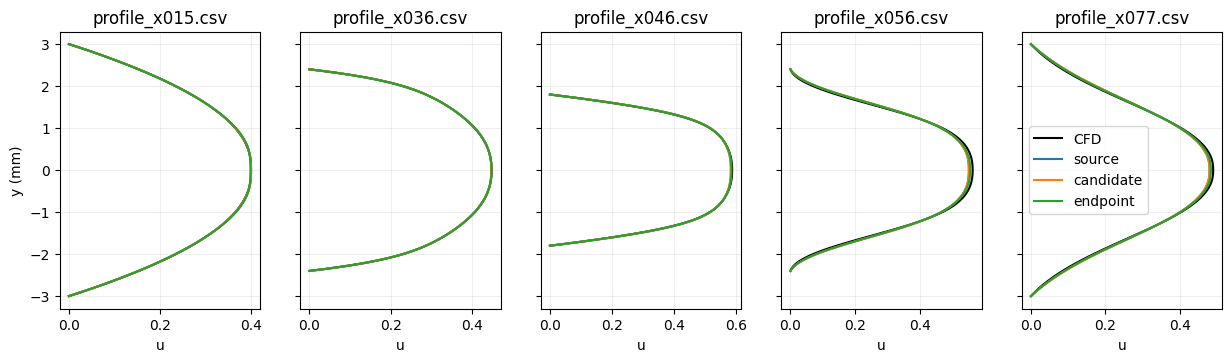

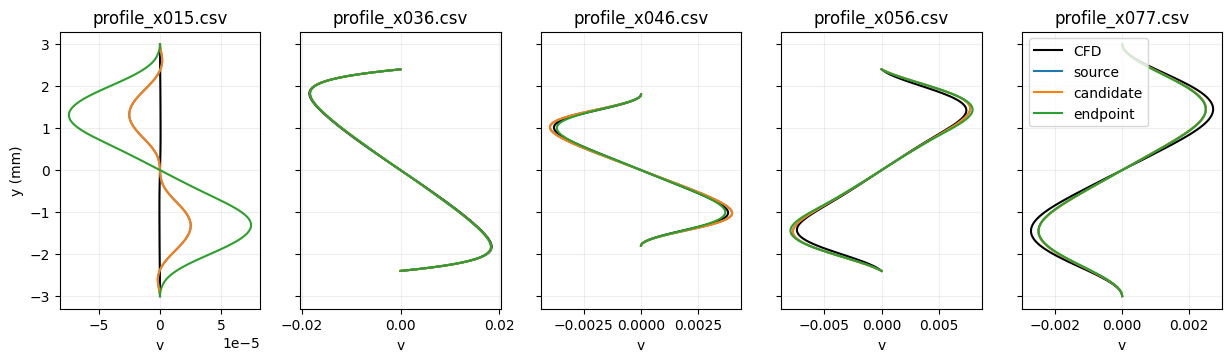

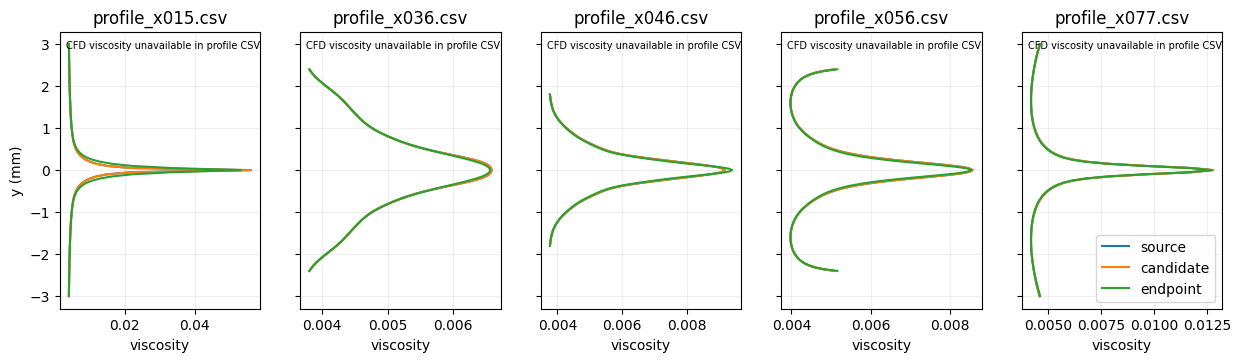

/tmp/ipykernel_48/2804751405.py:64: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  im=ax.pcolormesh(X,Y,arr,shading='auto',cmap='coolwarm' if quantity=='v' or 'minus' in title else 'viridis',rasterized=True)


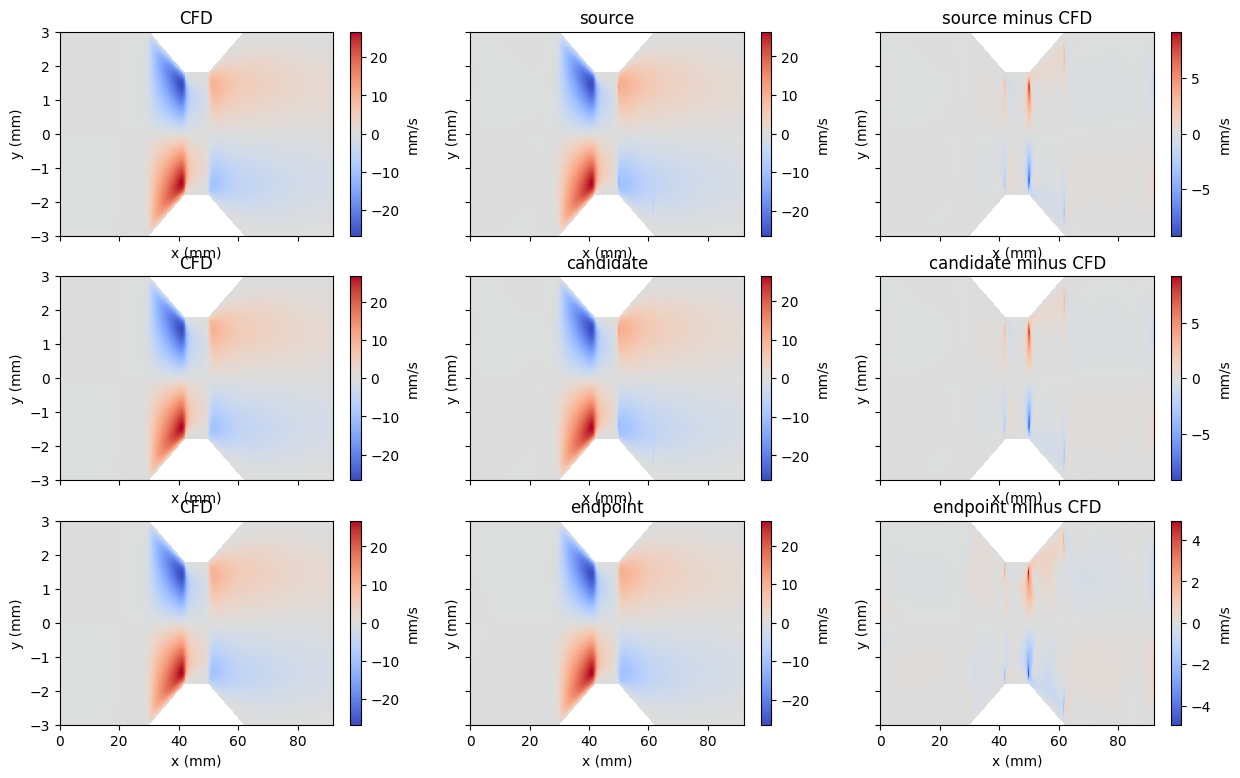

/tmp/ipykernel_48/2804751405.py:64: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  im=ax.pcolormesh(X,Y,arr,shading='auto',cmap='coolwarm' if quantity=='v' or 'minus' in title else 'viridis',rasterized=True)


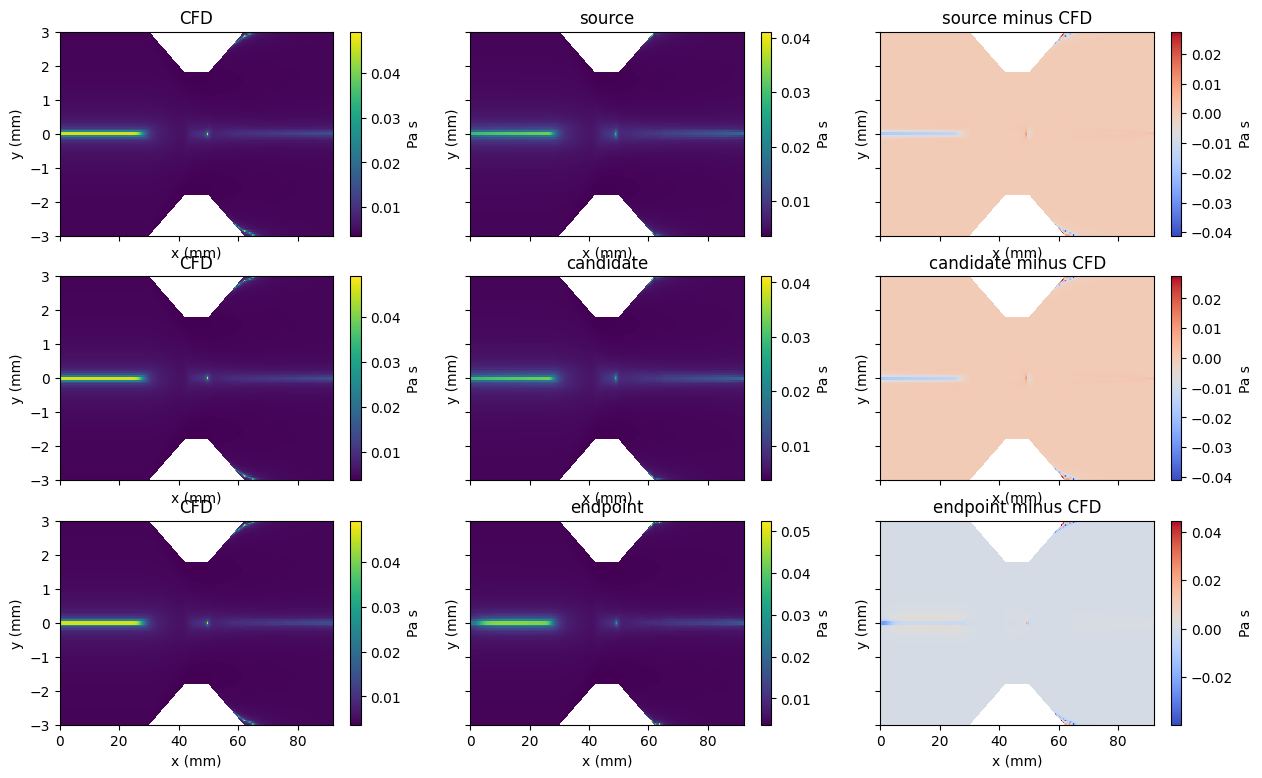

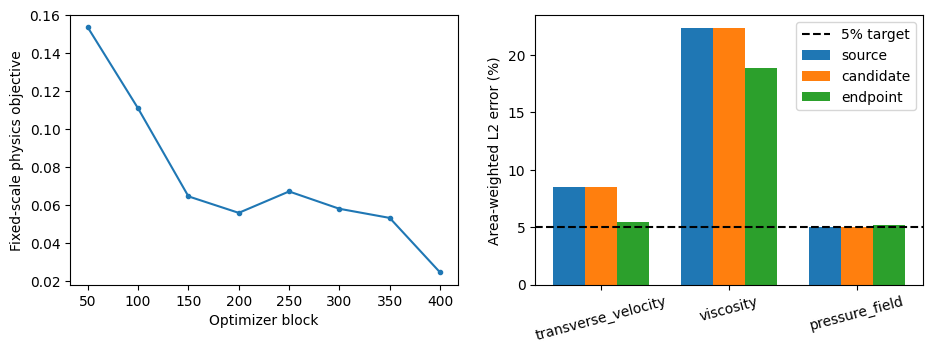

Results archive: /kaggle/working/st40_integrated_shear_v1_Results.zip
Save the notebook version with output files. No further training is launched.


In [14]:
eta_grid=FIELD.y.to_numpy().reshape(nx,ny)/hcol[:,None]
eta=eta_grid[0]
assert np.allclose(eta_grid,eta[None,:],atol=1e-7), 'Need a tensor grid in normalized eta for this diagnostic.'
hp=np.gradient(hcol,xcol,edge_order=2)
def grid_viscosity(u,v):
    um=np.asarray(u).reshape(nx,ny); vm=np.asarray(v).reshape(nx,ny)
    ue=np.gradient(um,eta,axis=1,edge_order=2); ve=np.gradient(vm,eta,axis=1,edge_order=2)
    ux=np.gradient(um,xcol,axis=0,edge_order=2)-eta[None,:]*hp[:,None]/hcol[:,None]*ue
    vx=np.gradient(vm,xcol,axis=0,edge_order=2)-eta[None,:]*hp[:,None]/hcol[:,None]*ve
    uy=ue/hcol[:,None]; vy=ve/hcol[:,None]
    gamma=np.sqrt(2*ux**2+2*vy**2+(uy+vx)**2)
    return (ETA_INF+(ETA0-ETA_INF)*(1+(LAM*gamma)**YASUDA_A)**((POWER_N-1)/YASUDA_A)).ravel()
fd_ref=grid_viscosity(FIELD.u,FIELD.v)
fd_report={'CFD_grid_gradient_mu_vs_export_percent':wrel(fd_ref,FIELD.viscosity)}
region=np.searchsorted(np.array(_xs),FIELD.x.to_numpy(),side='right')
eta_abs=np.abs(FIELD.y.to_numpy()/geometry.half_height(FIELD.x.to_numpy()))
spatial=[]
for case,fp in all_fields.items():
    fd_mu=grid_viscosity(fp[:,0],fp[:,1])
    fd_report[case+'_same_grid_gradient_mu_vs_CFD_percent']=wrel(fd_mu,FIELD.viscosity)
    for rid in range(5):
        for band,lo,hi in [('core',0,.05),('middle',.05,.75),('outer',.75,1.01)]:
            mask=(region==rid)&(eta_abs>=lo)&(eta_abs<hi)
            if not mask.any(): continue
            w=AREA[mask]
            spatial.append(dict(case=case,region=rid,band=band,
                v_L2_percent=wrel(fp[mask,1],FIELD.v.to_numpy()[mask],w),
                v_absolute_rms_mm_s=1000*wrms(fp[mask,1]-FIELD.v.to_numpy()[mask],w),
                viscosity_L2_percent=wrel(fp[mask,3],FIELD.viscosity.to_numpy()[mask],w)))
pd.DataFrame(spatial).to_csv(OUT/'metrics/spatial_errors.csv',index=False)
write_json(OUT/'metrics/mesh_gradient_diagnostic.json',fd_report)
display(pd.DataFrame(spatial)); display(pd.Series(fd_report))

def savefig(fig,name):
    fig.savefig(OUT/'figures'/f'{name}.png',dpi=220,bbox_inches='tight')
    fig.savefig(OUT/'figures'/f'{name}.pdf',bbox_inches='tight'); plt.show()
for quantity,col in [('u',0),('v',1),('viscosity',3)]:
    fig,axs=plt.subplots(1,5,figsize=(15,3.6),sharey=True)
    for ax,(name,prof) in zip(axs,PROFILES):
        if quantity in prof.columns:
            ax.plot(prof[quantity], prof.y*1000, 'k-', label='CFD')
        else:
            ax.text(
            0.03, 0.97,
            f"CFD {quantity} unavailable in profile CSV",
            transform=ax.transAxes,
            va="top",
            fontsize=7,
            )
        for case in all_fields:
            pp=pd.read_csv(OUT/'fields'/f'{case}_{name}')
            ax.plot(pp['pinn_'+quantity],pp.y*1000,label=case)
        ax.set_title(name); ax.set_xlabel(quantity); ax.grid(alpha=.2)
    axs[0].set_ylabel('y (mm)'); axs[-1].legend(); savefig(fig,'five_profiles_'+quantity)

X=FIELD.x.to_numpy().reshape(nx,ny)*1000; Y=FIELD.y.to_numpy().reshape(nx,ny)*1000
for quantity,col,unit in [('v',1,'mm/s'),('viscosity',3,'Pa s')]:
    fig,axs=plt.subplots(3,3,figsize=(15,9),sharex=True,sharey=True)
    multiplier=1000 if quantity=='v' else 1
    ref=FIELD[quantity].to_numpy().reshape(nx,ny)*multiplier
    for row,case in enumerate(['source','candidate','endpoint']):
        pred=all_fields[case][:,col].reshape(nx,ny)*multiplier
        for ax,arr,title in zip(axs[row],[ref,pred,pred-ref],['CFD',case,case+' minus CFD']):
            im=ax.pcolormesh(X,Y,arr,shading='auto',cmap='coolwarm' if quantity=='v' or 'minus' in title else 'viridis',rasterized=True)
            fig.colorbar(im,ax=ax,label=unit); ax.set_title(title); ax.set_xlabel('x (mm)'); ax.set_ylabel('y (mm)')
    savefig(fig,'field_'+quantity)

fig,axs=plt.subplots(1,2,figsize=(11,3.5))
if history:
    axs[0].plot([h['block'] for h in history],[h['loss'] for h in history],'.-')
    axs[0].set_xlabel('Optimizer block'); axs[0].set_ylabel('Fixed-scale physics objective')
names=['transverse_velocity','viscosity','pressure_field']
xx=np.arange(len(names))
for j,case in enumerate(['source','candidate','endpoint']): axs[1].bar(xx+(j-1)*.25,[metrics[case][n] for n in names],width=.25,label=case)
axs[1].axhline(5,color='k',ls='--',label='5% target'); axs[1].set_xticks(xx,names,rotation=15)
axs[1].set_ylabel('Area-weighted L2 error (%)'); axs[1].legend(); savefig(fig,'training_and_gates')

archive=shutil.make_archive(str(OUT)+'_Results','zip',root_dir=OUT)
print('Results archive:',archive)
print('Save the notebook version with output files. No further training is launched.')